In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 최신 NumPy에서 권장하는 권장 난수 생성 방식
rand = np.random.default_rng(0)

# uniform(170, 190, 50) : 170부터 190 사이의 숫자 중에서 총 50개의 무작위 온도 값을 균등한 확률로 뽑아낸다.
# reshape(-1, 1) : 무한층, 1개호의 2차원 리스트 생성 - scikit-learn 은 입력 데이터는 반드시 2차원 형태
x = rand.uniform(170, 190, 50).reshape(-1, 1)                   # 공정 온도(℃)

# 온도가 0℃일 때 기본 치수가 9.3mm이고, 온도가 1℃ 오를 때마다 치수가 0.004mm씩 커진다는 규칙
# x.ravel(): 받아온  x 를 1차원으로 쭉 펴준다.
# rand.normal(0, 0.005, 50) : 기계의 미세한 흔들림이나 측정 오차를 흉내 내기 위한 노이즈(잡음)
# 평균이 0이고 표준편차가 0.005인 미세한 오차 50개
y = 9.3 + 0.004 * x.ravel() + rand.normal(0, 0.005, 50)          # 치수(mm)



In [2]:
model = LinearRegression().fit(x, y)
print(f'계수 a = {model.coef_[0]:.4f}, 절편 b = {model.intercept_:.3f}')
# 공정 온도가 185℃일 때, 제품 치수는 얼마가 될 것 같아?"
print('온도 185℃ 예측 치수 :', model.predict([[185]])[0].round(4))

계수 a = 0.0041, 절편 b = 9.277
온도 185℃ 예측 치수 : 10.0407


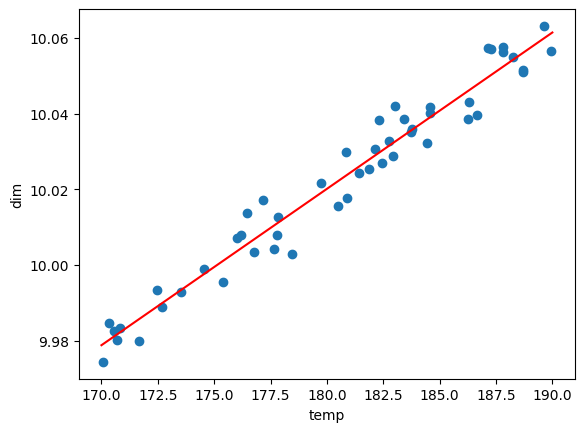

In [4]:
# 170~190 도 까지 변화에 치수는 얼마나 늘어나는 가를 그래프로 표현
line = np.linspace(170, 190, 100).reshape(-1, 1)
plt.scatter(x, y)
plt.plot(line, model.predict(line), 'r')
plt.xlabel('temp')
plt.ylabel('dim')
plt.show()